# 🧠 Tutorial 4 - CNNs: From a Single Convolution to Modern Architectures

Course: Applied Deep Learning (ECE1553) - FALL 2026
Instructor: Dr. Ali Breyhi
Tutorial: Saleh Tabatabaei (This TUT: **Cassie Li**)

By the end of this tutorial you will be able to:

In this session we build up convolutional neural networks step by step: we start with what a single convolution does to an image, train our own small CNN on MNIST, look inside a big pretrained network (**AlexNet**), and finish with **ResNet** and transfer learning. Optional sections at the end cover the modern CNN "zoo", Grad-CAM explanations, data augmentation and **U-Net** for segmentation.

### Learning goals
By the end you should be able to:
1. Explain what `nn.Conv2d` computes and predict output shapes from kernel size, padding and stride.
2. Build and train a small CNN in PyTorch.
3. Load a pretrained model, inspect its layers and feature maps, and use it for prediction.
4. Explain residual connections and fine-tune a pretrained ResNet on a new task.

### Before you start
* `Runtime → Change runtime type → GPU`. Everything also runs on a CPU, just slower.
* Put `cat.jpg`, `dog.jpg` and the four MNIST files (`train-images-idx3-ubyte`, …) in the same folder as this notebook. If the MNIST files are missing, torchvision downloads them.
* Pretrained weights (AlexNet ≈ 233 MB, ResNet-18 ≈ 45 MB) are downloaded once from the internet.


---
## 0. Setup

In [67]:
import os, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models
from torch.utils.data import DataLoader, Subset, TensorDataset
from PIL import Image
from tqdm.auto import tqdm

%matplotlib inline

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

# FAST = True keeps every training run short enough for a 50-minute class.
# Set it to False at home for longer / full-dataset training.
FAST = True
results = {}   # we collect test accuracies here to compare models at the end

PyTorch 2.14.1 | torchvision 0.29.1 | device: cpu


In [68]:
# Use the MNIST files shipped with the tutorial (if present) instead of downloading them.
# torchvision looks for them in  <root>/MNIST/raw/
RAW = os.path.join("data", "MNIST", "raw")
os.makedirs(RAW, exist_ok=True)
for name in ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
             "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]:
    for ext in ["", ".gz"]:
        if os.path.exists(name + ext) and not os.path.exists(os.path.join(RAW, name + ext)):
            shutil.copy(name + ext, RAW)
print("MNIST raw folder:", sorted(os.listdir(RAW)))

for img_file in ["cat.jpg", "dog.jpg"]:
    print(img_file, "found" if os.path.exists(img_file) else "MISSING - please upload it next to the notebook")

MNIST raw folder: ['t10k-images-idx3-ubyte', 't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte', 'train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte', 'train-labels-idx1-ubyte.gz']
cat.jpg found
dog.jpg found


In [69]:
# Two small helpers we use throughout the notebook
def show(t, title=None, ax=None, cmap="gray"):
    """Display a tensor shaped (H,W), (C,H,W) or (1,C,H,W).
    Values are min-max scaled to [0,1] first: conv outputs can be negative or > 1."""
    t = t.detach().cpu().float()
    if t.dim() == 4: t = t[0]
    t = (t - t.min()) / (t.max() - t.min() + 1e-8)
    if t.dim() == 3:
        t = t.permute(1, 2, 0) if t.shape[0] == 3 else t[0]
    ax = ax or plt.gca()
    ax.imshow(t.numpy(), cmap=cmap)
    if title: ax.set_title(title, fontsize=9)
    ax.axis("off")

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

---
## Part 1 — Convolution fundamentals

### 1.1 Images are tensors

PIL size (W, H): (202, 185) | mode: RGB


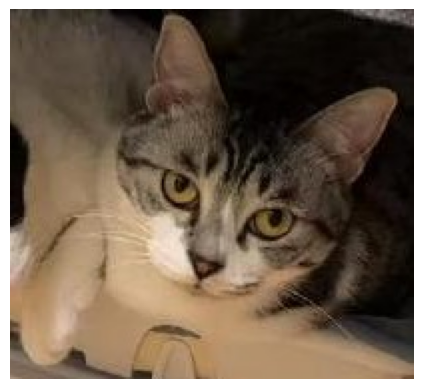

In [70]:
img = Image.open("cat.jpg").convert("RGB")
# img = img.convert('L')  # convert to gray image. 'L' means luminance
print("PIL size (W, H):", img.size, "| mode:", img.mode)
plt.imshow(img)
plt.axis("off")
plt.show()

In [71]:
preprocess = transforms.Compose([
    transforms.Resize((480, 480)),  # Resize the image to a fixed size
    transforms.ToTensor(),          # PIL image (H,W,C) in [0,255]  ->  tensor (C,H,W) in [0,1]
])
x = preprocess(img).unsqueeze(0)    # Add batch dimension
x.shape                             # (batch_size, channel, height, width) == NCHW format

torch.Size([1, 3, 480, 480])

💡 **PyTorch uses the NCHW format** for convolutional layers: **N**umber of images in the batch, **C**hannels, **H**eight, **W**idth. Layers always expect a batch, which is why we called `unsqueeze(0)`.

Two ways to build a batch:

In [72]:
images = [x, x]
print("x's shape:", x.shape)
print("torch.cat  (joins along an existing dim):", torch.cat(images).shape)
print("torch.stack (creates a new dim)         :", torch.stack(images).shape)
print("x[0]'s shape:", x[0].shape)
print("torch.stack (creates a new dim)         :", torch.stack([x[0], x[0]]).shape)

x's shape: torch.Size([1, 3, 480, 480])
torch.cat  (joins along an existing dim): torch.Size([2, 3, 480, 480])
torch.stack (creates a new dim)         : torch.Size([2, 1, 3, 480, 480])
x[0]'s shape: torch.Size([3, 480, 480])
torch.stack (creates a new dim)         : torch.Size([2, 3, 480, 480])


x = [1, 3, 480, 480]

x = [1, 3, 480, 480]

**torch.cat([x, x]): concatenate dimension 0**

result = [2, 3, 480, 480]


x[0] removes the batch dimension --> x[0] = [3, 480, 480]

**torch.stack ([x[0], x[0]]): takes the two tensors and creates a new dimension**

result = [2, 3, 480, 480]

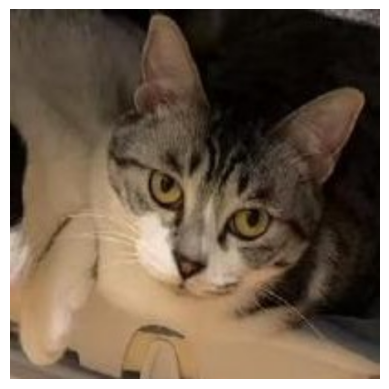

In [73]:
# ...and back from tensor to image
to_pil = transforms.ToPILImage()
output = to_pil(x.squeeze(0))
plt.imshow(output)
plt.axis("off")
plt.show()

### 1.2 What does a convolution compute?

A conv layer slides a small **kernel** (a learnable weight tensor) over the input. At each position it multiplies the kernel element-wise with the patch underneath and sums everything up:

$$y[o, i, j] = \sum_{c}\sum_{u}\sum_{v} w[o, c, u, v]\; x[c,\; i\cdot s + u,\; j\cdot s + v] \;+\; b[o]$$

The same weights are reused at every location (**weight sharing**), so a conv layer is tiny compared to a fully connected layer.


- **Kernel size** determines how large a local region the convolution looks at each time, such as a $3 \times 3$ or $5 \times 5$ window.
- **Padding** adds extra pixels around the input, usually to control how much the spatial dimensions shrink. Larger padding shrinks less and preserves the spatial size.
- **Stride** determines how many pixels the kernel moves at each step, with larger strides producing smaller output feature maps.

For one spatial dimension:

$$
\text{Output Size}
=
\left\lfloor
\frac{\text{Input Size} + 2\text{Padding} - \text{Kernel Size}}
{\text{Stride}}
\right\rfloor
+ 1
$$

For a 2D convolution:

$$
H_{\text{out}}
=
\left\lfloor
\frac{H_{\text{in}} + 2P_H - K_H}{S_H}
\right\rfloor
+ 1
$$

$$
W_{\text{out}}
=
\left\lfloor
\frac{W_{\text{in}} + 2P_W - K_W}{S_W}
\right\rfloor
+ 1
$$

In [74]:
conv = nn.Conv2d(in_channels=1,
                 out_channels=2,
                 kernel_size=3,
                 stride=1,
                 bias=False,
                 padding=0)
kernel = list(conv.parameters())[0]   # same as conv.weight
print(conv)
print("kernel shape:", kernel.shape)  # (out_channels, in_channels, kernel_size, kernel_size)

Conv2d(1, 2, kernel_size=(3, 3), stride=(1, 1), bias=False)
kernel shape: torch.Size([2, 1, 3, 3])


In [75]:
# Let's re-implement the convolution with plain loops and check that we get the same numbers.
def conv2d_manual(x, w, stride=1, padding=0):
    """x: (C_in, H, W), w: (C_out, C_in, K, K)  ->  (C_out, H_out, W_out)"""
    x = F.pad(x, (padding, padding, padding, padding))
    C_out, C_in, K, _ = w.shape
    H_out = (x.shape[1] - K) // stride + 1
    W_out = (x.shape[2] - K) // stride + 1
    out = torch.zeros(C_out, H_out, W_out)
    for o in range(C_out):
        for i in range(H_out):
            for j in range(W_out):
                patch = x[:, i*stride:i*stride+K, j*stride:j*stride+K]
                out[o, i, j] = (patch * w[o]).sum()
    return out

toy = torch.randn(1, 1, 6, 6)
with torch.no_grad():
    y_torch = conv(toy)[0]
    y_manual = conv2d_manual(toy[0], conv.weight)
print("output shape:", y_torch.shape)
print("same result? ", torch.allclose(y_torch, y_manual, atol=1e-6))

output shape: torch.Size([2, 4, 4])
same result?  True


💡 Strictly speaking, PyTorch computes a *cross-correlation* (the kernel is not flipped). For learned kernels this makes no difference — the network simply learns the flipped version.

### 1.3 Hand-designed kernels: edges and blur
Before deep learning, people designed kernels by hand. A CNN *learns* such kernels from data.

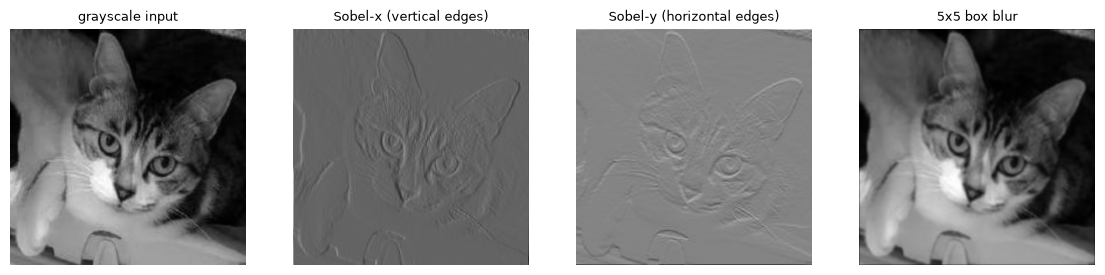

In [76]:
x_gray = x.mean(dim=1, keepdim=True)                 # (1, 1, H, W) grayscale

sobel_x = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])
blur = torch.ones(5, 5) / 25 # 5x5 box blur with all 1's and normalized to sum to 1

edge_conv = nn.Conv2d(1, 2, kernel_size=3, padding=1, bias=False)
blur_conv = nn.Conv2d(1, 1, kernel_size=5, padding=2, bias=False)
with torch.no_grad():
    edge_conv.weight[0, 0] = sobel_x      # responds to vertical edges
    edge_conv.weight[1, 0] = sobel_x.T    # responds to horizontal edges
    blur_conv.weight[0, 0] = blur
    edges = edge_conv(x_gray)
    blurred = blur_conv(x_gray)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
show(x_gray, "grayscale input", axes[0])
show(edges[:, 0], "Sobel-x (vertical edges)", axes[1])
show(edges[:, 1], "Sobel-y (horizontal edges)", axes[2])
show(blurred, "5x5 box blur", axes[3])
plt.show()

### 1.4 A conv layer on an RGB image (random weights)
With `in_channels=3`, each kernel has shape `3 × K × K` and sums over **all** input channels. A freshly created layer has random weights, so the output looks like a random filter.

weight shape: torch.Size([1, 3, 25, 25])
input : torch.Size([1, 3, 480, 480]) 
output: torch.Size([1, 1, 480, 480])


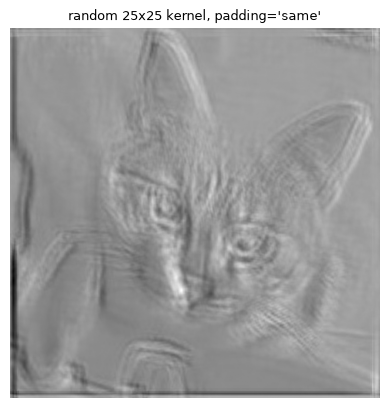

In [77]:
kernel_size = 25

# in_channels = 3 because the input image has three channels: RGB
conv_layer = nn.Conv2d(in_channels=3,
                       out_channels=1,
                       kernel_size=kernel_size,
                       padding="same",   # or 'valid' or a non-negative integer
                       bias=False)
print("weight shape:", conv_layer.weight.data.shape)

y = conv_layer(x)
print("input :", x.shape, "\noutput:", y.shape)   # 'same' keeps H and W
show(y, "random 25x25 kernel, padding='same'")
plt.show()

### 1.5 Output size: padding and stride

$$H_{out} = \left\lfloor \frac{H_{in} + 2P - K}{S} \right\rfloor + 1$$

* **Padding (P)** adds a border of zeros → keeps spatial size, lets the kernel see the edges.
* **Stride (S)** moves the kernel S pixels at a time → downsamples.

In [78]:
def conv_out(n, k, p=0, s=1):
    return (n + 2 * p - k) // s + 1

print("No padding, K=3 on 6x6 :", conv_out(6, 3))           # the toy example above -> 4
print("K=25, 'same' on 480     :", conv_out(480, 25, p=12))  # 'same' means P = (K-1)/2

No padding, K=3 on 6x6 : 4
K=25, 'same' on 480     : 480


output: torch.Size([1, 1, 668, 668]) | formula: 668


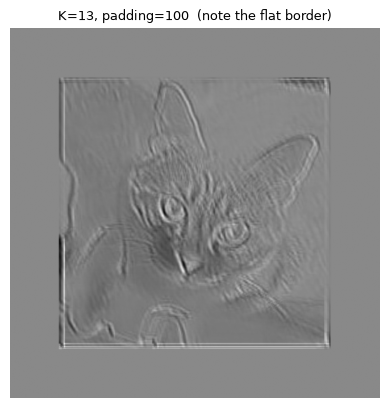

In [79]:
# ---- Padding ----
kernel_size = 13
padding = 100
conv_layer = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=kernel_size, padding=padding, bias=False)
y = conv_layer(x)
print("output:", y.shape, "| formula:", conv_out(480, kernel_size, p=padding))
show(y, f"K={kernel_size}, padding={padding}  (note the flat border)")
plt.show()

output: torch.Size([1, 1, 115, 115]) | formula: 115


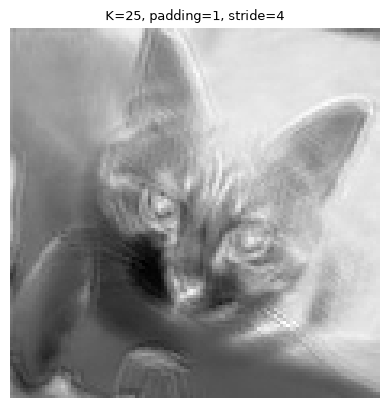

In [15]:
# ---- Stride ----
kernel_size = 25
padding = 1
stride = 4
conv_layer = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=kernel_size,
                       padding=padding, stride=stride, bias=False)
y = conv_layer(x)
print("output:", y.shape, "| formula:", conv_out(480, kernel_size, p=padding, s=stride))
show(y, f"K={kernel_size}, padding={padding}, stride={stride}")
plt.show()

🧪 **Quick check:** AlexNet's first layer takes a 224×224 image with `kernel_size=11, stride=4, padding=2`. What is the output size?

<details><summary>Answer</summary>

`(224 + 2·2 − 11) // 4 + 1 = 55` → 55×55. We'll confirm this in Part 3.
</details>

### 1.6 Pooling
Pooling summarises a neighbourhood with a fixed function (max or average). It has **no learnable parameters**, adds some robustness to small shifts, and (with stride > 1) downsamples.

MaxPool k=10, s=1: torch.Size([1, 1, 106, 106])
MaxPool k=2      : torch.Size([1, 1, 57, 57])


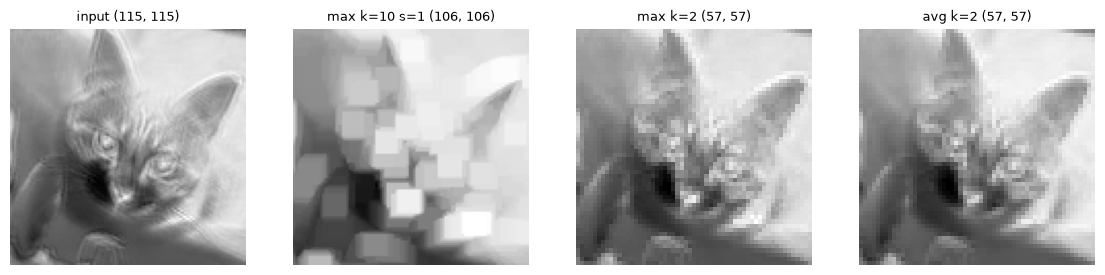

In [16]:
pool = nn.MaxPool2d(kernel_size=10, stride=1)   # original example: big window, no downsampling
z = pool(y)
print("MaxPool k=10, s=1:", z.shape)

z_max = nn.MaxPool2d(kernel_size=2)(y)          # the usual choice: halves H and W (stride defaults to kernel_size)
z_avg = nn.AvgPool2d(kernel_size=2)(y)
print("MaxPool k=2      :", z_max.shape)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
show(y, f"input {tuple(y.shape[-2:])}", axes[0])
show(z, f"max k=10 s=1 {tuple(z.shape[-2:])}", axes[1])
show(z_max, f"max k=2 {tuple(z_max.shape[-2:])}", axes[2])
show(z_avg, f"avg k=2 {tuple(z_avg.shape[-2:])}", axes[3])
plt.show()

### 1.7 Why convolutions? Count the parameters

In [17]:
# Map a 224x224x3 image to 64 feature maps of the same size
conv64 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
n_in, n_out = 3 * 224 * 224, 64 * 224 * 224
print(f"Conv2d(3, 64, 3x3)       : {count_params(conv64):>20,} parameters")
print(f"Fully connected equivalent: {n_in * n_out + n_out:>20,} parameters")

Conv2d(3, 64, 3x3)       :                1,792 parameters
Fully connected equivalent:      483,388,358,656 parameters


💡 **Weight sharing + local connectivity** make convolutions dramatically cheaper and give them a built-in assumption that matters for images: *the same pattern can appear anywhere*.

---
## Part 2 — Your first CNN: MNIST

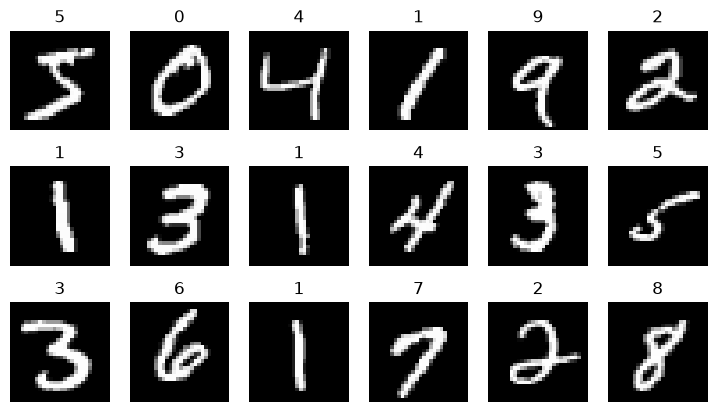

In [18]:
# plot the first 18 images in the training data
mnist = datasets.MNIST("data", download=True, train=True)
plt.figure(figsize=(9, 5))
for k in range(18):
    image, label = mnist[k]          # PIL image, int label
    plt.subplot(3, 6, k + 1)
    plt.imshow(image, cmap="gray")
    plt.title(label)
    plt.axis("off")
plt.show()

Our network has two **conv → ReLU → max-pool** blocks followed by one linear classifier:

```
Input Image (1 x 28 x 28)
   ↓  Convolution (5 filters, 5×5)       -> 5 x 24 x 24
   ↓  ReLU Activation (non-linearity)
   ↓  Max Pooling (2×2, downsample)      -> 5 x 12 x 12
   ↓  Convolution (4 filters, 5×5)       -> 4 x 8 x 8
   ↓  ReLU + Max Pooling (2×2)           -> 4 x 4 x 4
   ↓  Flatten                            -> 64
   ↓  Linear                             -> 10 class scores
```

In [19]:
class MNIST_CNN(nn.Module):
    def __init__(self):
        super(MNIST_CNN, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=5, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=5, out_channels=4, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.fc = nn.Linear(4 * 4 * 4, 10)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = x.reshape(x.size(0), -1)   # flatten: (N, 4, 4, 4) -> (N, 64)
        x = self.fc(x)
        return x

In [20]:
model = MNIST_CNN().to(device)
print(model)
print(f"\nTotal parameters: {count_params(model):,}")

# Trace the shapes through the network
h = torch.zeros(1, 1, 28, 28, device=device)
print("\ninput        ", tuple(h.shape))
h = model.layer1(h); print("after layer1 ", tuple(h.shape))
h = model.layer2(h); print("after layer2 ", tuple(h.shape))
h = h.reshape(1, -1); print("flattened    ", tuple(h.shape))
h = model.fc(h);      print("logits       ", tuple(h.shape))

MNIST_CNN(
  (layer1): Sequential(
    (0): Conv2d(1, 5, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(5, 4, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Linear(in_features=64, out_features=10, bias=True)
)

Total parameters: 1,284

input         (1, 1, 28, 28)
after layer1  (1, 5, 12, 12)
after layer2  (1, 4, 4, 4)
flattened     (1, 64)
logits        (1, 10)


🧪 **Quick check:** where does `4 * 4 * 4` in `nn.Linear` come from? What would change if we used `padding=2` in both convolutions?

<details><summary>Answer</summary>

28 → conv5 → 24 → pool → 12 → conv5 → 8 → pool → 4, with 4 channels: 4·4·4 = 64.
With `padding=2` the convs keep the size: 28 → 28 → 14 → 14 → 7, so the linear layer would need `4 * 7 * 7` inputs.
</details>

### Training

In [21]:
lr = 1e-3
epochs = 3 if FAST else 5
batch_size = 64

transform = transforms.Compose([
    transforms.ToTensor(),                       # first, convert image to PyTorch tensor
    transforms.Normalize((0.1307,), (0.3081,))   # normalize inputs (MNIST mean and std)
])

mnist_train = datasets.MNIST("data", download=True, train=True, transform=transform)
mnist_test = datasets.MNIST("data", download=True, train=False, transform=transform)

train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=batch_size, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = torch.nn.CrossEntropyLoss()

history = {"train_loss": [], "test_loss": [], "test_acc": []}
for epoch in range(epochs):
    # ---- Training step ----
    model.train()
    train_loss = []
    for i, (data, labels) in tqdm(enumerate(train_loader), total=len(train_loader), leave=False):
        data, labels = data.to(device), labels.to(device)
        outputs = model(data)                 # 1. forward pass
        loss = criterion(outputs, labels)     # 2. compute loss
        optimizer.zero_grad()                 # 3. reset old gradients
        loss.backward()                       # 4. backpropagation
        optimizer.step()                      # 5. update weights
        train_loss.append(loss.item())

    # ---- Evaluate on the test set ----
    model.eval()
    test_loss, test_accuracy = [], []
    with torch.no_grad():                     # no gradients needed for evaluation
        for data, labels in test_loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            _, predicted = torch.max(outputs, 1)
            test_loss.append(criterion(outputs, labels).item())
            test_accuracy.append((predicted == labels).sum().item() / predicted.size(0))

    history["train_loss"].append(np.mean(train_loss))
    history["test_loss"].append(np.mean(test_loss))
    history["test_acc"].append(np.mean(test_accuracy))
    print(f"Epoch: {epoch}, train loss: {np.mean(train_loss):.4f}, "
          f"test loss: {np.mean(test_loss):.4f}, test accuracy: {np.mean(test_accuracy):.4f}")

results["Small CNN (ours)"] = 100 * history["test_acc"][-1]

  0%|          | 0/938 [00:00<?, ?it/s]

Epoch: 0, train loss: 0.4571, test loss: 0.1707, test accuracy: 0.9476


  0%|          | 0/938 [00:00<?, ?it/s]

Epoch: 1, train loss: 0.1674, test loss: 0.1260, test accuracy: 0.9594


  0%|          | 0/938 [00:00<?, ?it/s]

Epoch: 2, train loss: 0.1321, test loss: 0.1016, test accuracy: 0.9680


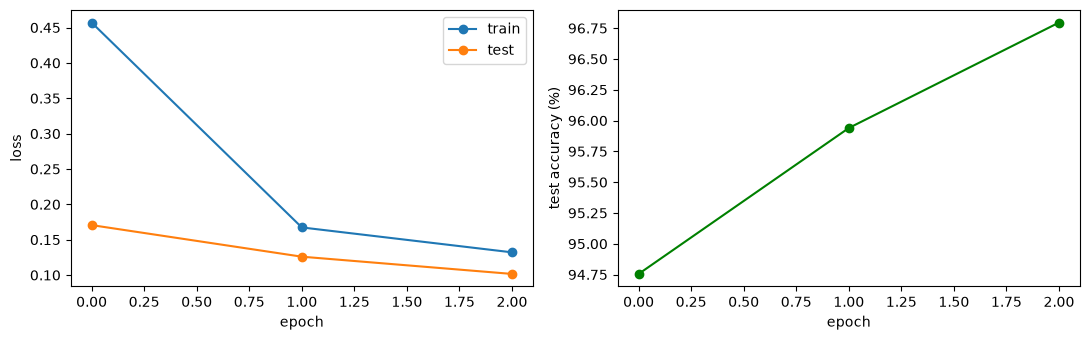

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history["train_loss"], "o-", label="train")
axes[0].plot(history["test_loss"], "o-", label="test")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[1].plot(np.array(history["test_acc"]) * 100, "o-", color="green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("test accuracy (%)")
plt.tight_layout(); plt.show()

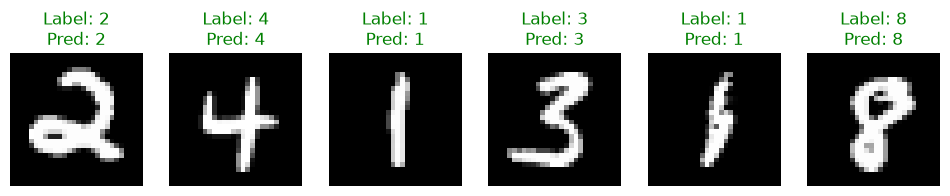

In [23]:
# Randomly select 6 images from the test set
def select_random_images(dataset, num_images=6):
    indices = random.sample(range(len(dataset)), num_images)
    images, labels = zip(*[dataset[i] for i in indices])
    return images, labels

# Function to display the images with predictions
def plot_images(images, labels, predictions):
    fig, axes = plt.subplots(1, len(images), figsize=(12, 3))
    for i, (image, label, prediction) in enumerate(zip(images, labels, predictions)):
        axes[i].imshow(image.squeeze(), cmap="gray")
        color = "green" if label == prediction else "red"
        axes[i].set_title(f"Label: {label}\nPred: {prediction}", color=color)
        axes[i].axis("off")
    plt.show()

# Set the model to evaluation mode
model.eval()

# Select 6 random images from the test set and batch them
test_images, test_labels = select_random_images(mnist_test)
test_images_tensor = torch.stack([image for image in test_images]).to(device)

# Perform predictions on the selected images
with torch.no_grad():
    outputs = model(test_images_tensor)
    _, predicted_labels = torch.max(outputs, 1)

plot_images(test_images, list(test_labels), predicted_labels.cpu().numpy())

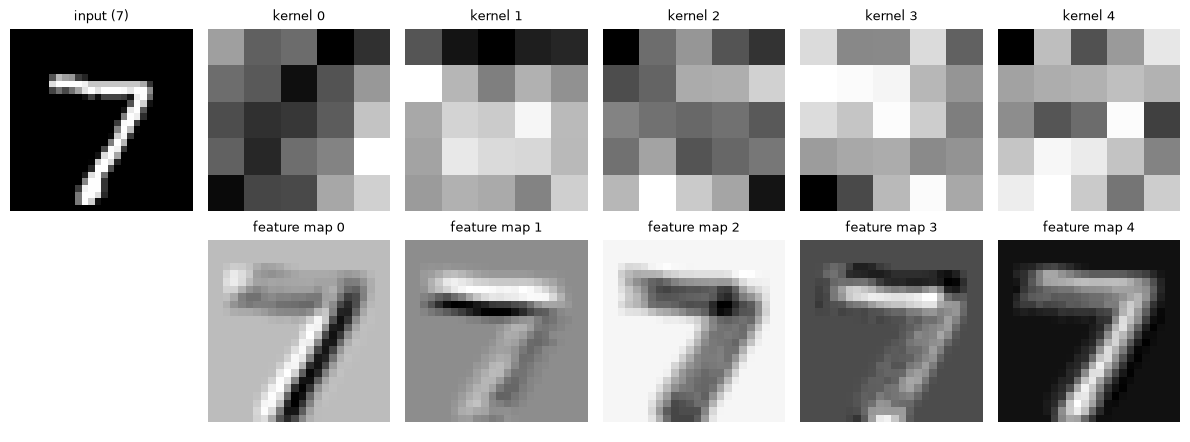

In [24]:
# What did the first layer learn? Its 5 kernels, and what they produce on one digit
digit, label = mnist_test[0]
with torch.no_grad():
    maps = model.layer1[0](digit.unsqueeze(0).to(device))   # conv only, before ReLU

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
show(digit, f"input ({label})", axes[0, 0]); axes[1, 0].axis("off")
for k in range(5):
    show(model.layer1[0].weight[k, 0], f"kernel {k}", axes[0, k + 1])
    show(maps[0, k], f"feature map {k}", axes[1, k + 1])
plt.tight_layout(); plt.show()

🧪 **Try it (later):** increase the number of filters (e.g. 16 and 32), or add `nn.Dropout`. How do the parameter count and test accuracy change?

---
## Part 3 — Going big: AlexNet (2012)

Krizhevsky, Alex, Ilya Sutskever, and Geoffrey E. Hinton. *"ImageNet classification with deep convolutional neural networks."* NeurIPS 25 (2012). Cited by 134,560 as of October 22, 2024.

![](https://miro.medium.com/v2/resize:fit:1400/1*0dsWFuc0pDmcAmHJUh7wqg.png)

AlexNet won ImageNet 2012 by a huge margin and started the deep learning boom. Same building blocks as our MNIST CNN — just much bigger, plus a few tricks: **ReLU** instead of tanh, **dropout**, **data augmentation**, and training on **GPUs**.

**ImageNet (ILSVRC):** 1000 classes, 1,281,167 training images, 50,000 validation images and 100,000 test images.

In [25]:
# Get the weights from the torchvision library. The weights were trained on ImageNet.
alexnet_weights = models.AlexNet_Weights.DEFAULT
alexNet = models.alexnet(weights=alexnet_weights).to(device)
alexNet

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [26]:
alexNet.features      # the convolutional "feature extractor"

Sequential(
  (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU(inplace=True)
  (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): ReLU(inplace=True)
  (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
)

In [27]:
alexNet.classifier    # the fully connected classifier

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=9216, out_features=4096, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=4096, out_features=4096, bias=True)
  (5): ReLU(inplace=True)
  (6): Linear(in_features=4096, out_features=1000, bias=True)
)

In [28]:
n_feat, n_cls = count_params(alexNet.features), count_params(alexNet.classifier)
print(f"features  : {n_feat:>12,} params")
print(f"classifier: {n_cls:>12,} params  ({100 * n_cls / (n_feat + n_cls):.0f}% of the total!)")
print(f"total     : {count_params(alexNet):>12,} params  vs. {count_params(MNIST_CNN()):,} in our MNIST CNN")

features  :    2,469,696 params
classifier:   58,631,144 params  (96% of the total!)
total     :   61,100,840 params  vs. 1,284 in our MNIST CNN


💡 Almost all parameters sit in the fully connected layers, while almost all the *computation* happens in the convolutions. Later architectures (GoogLeNet, ResNet) replaced the large FC layers with **global average pooling** to save parameters.

### 3.1 Preprocessing for ImageNet models
A pretrained model expects inputs prepared **exactly like its training data**: 224×224 and normalised with the ImageNet mean/std.

In [29]:
imagenet_preprocess = transforms.Compose([
    transforms.Resize(256),                             # Resize the shorter side to 256
    transforms.CenterCrop(224),                         # Crop the center 224x224
    transforms.ToTensor(),                              # Convert to tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406],    # Normalize according to ImageNet
                         std=[0.229, 0.224, 0.225])
])
# (alexnet_weights.transforms() gives you an equivalent pipeline)

x = imagenet_preprocess(Image.open("cat.jpg").convert("RGB")).unsqueeze(0).to(device)
with torch.no_grad():
    features = alexNet.features(x)
print("input   :", x.shape)
print("features:", features.shape, "->", features.numel(), "numbers fed to the classifier (256*6*6)")

input   : torch.Size([1, 3, 224, 224])
features: torch.Size([1, 256, 6, 6]) -> 9216 numbers fed to the classifier (256*6*6)


### 3.2 What did the first layer learn?
The 64 first-layer kernels are 3×11×11, so we can display them as small RGB images. Compare them with the Sobel kernel from Part 1!

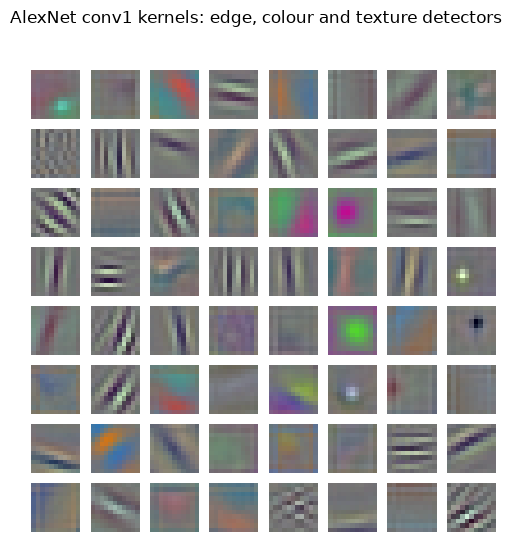

In [30]:
w = alexNet.features[0].weight.detach().cpu()      # (64, 3, 11, 11)
w = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(8, 8, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i].permute(1, 2, 0))
    ax.axis("off")
plt.suptitle("AlexNet conv1 kernels: edge, colour and texture detectors")
plt.show()

### 3.3 Feature maps after the first convolution

torch.Size([1, 64, 55, 55])


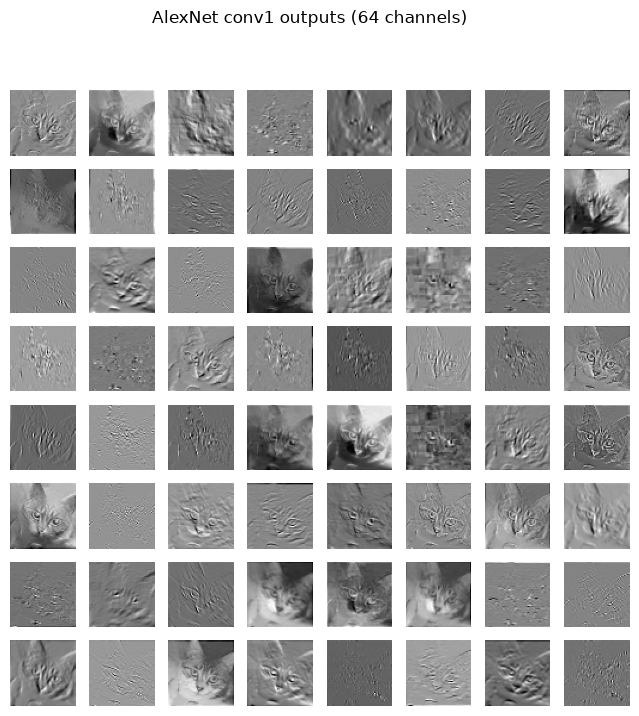

In [31]:
def plot_maps(y, n=64, title=None):
    """Plot the first n channels of a (1, C, H, W) activation tensor."""
    y = y.detach().cpu().numpy()
    y = (y - y.min()) / (y.max() - y.min())
    plt.figure(figsize=(8, 8))
    for i in range(n):
        plt.subplot(8, 8, i + 1)
        plt.imshow(y[0, i], cmap="gray")
        plt.axis("off")
    if title: plt.suptitle(title)
    plt.show()

alexNetConv = alexNet.features[0]
with torch.no_grad():
    y = alexNetConv(x)
print(y.shape)   # 55x55, as computed in the quick check of Part 1
plot_maps(y, title="AlexNet conv1 outputs (64 channels)")

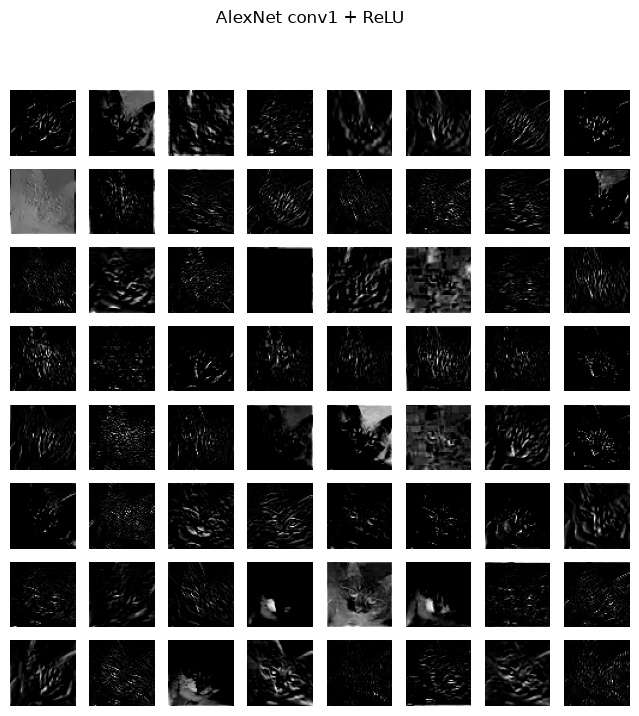

In [32]:
# After ReLU: negative responses are set to zero -> sparser, cleaner maps
with torch.no_grad():
    y = torch.relu(alexNetConv(x))
plot_maps(y, title="AlexNet conv1 + ReLU")

### 3.4 Going deeper: after the second conv block

torch.Size([1, 192, 13, 13])


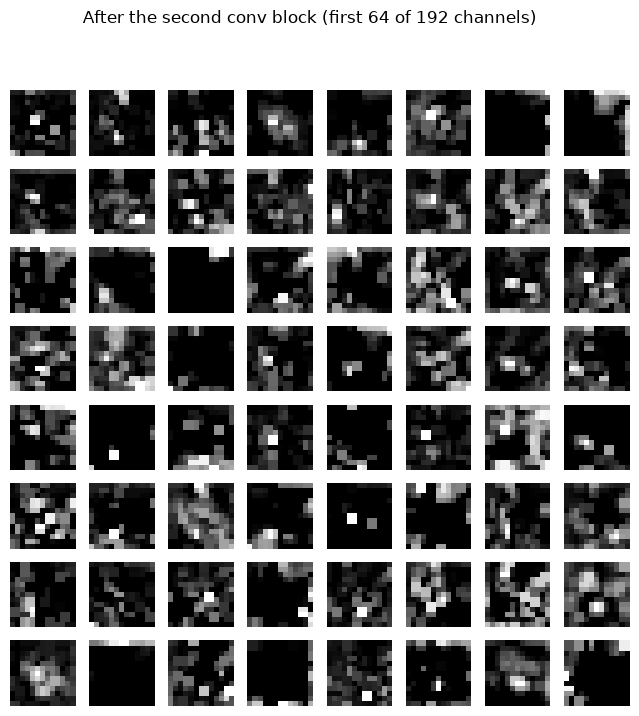

In [33]:
with torch.no_grad():
    y = alexNet.features[0](x)  # first conv
    y = alexNet.features[1](y)  # relu
    y = alexNet.features[2](y)  # pooling
    y = alexNet.features[3](y)  # second conv
    y = alexNet.features[4](y)  # relu
    y = alexNet.features[5](y)  # pooling
print(y.shape)   # 192 channels, 13x13
plot_maps(y, title="After the second conv block (first 64 of 192 channels)")

💡 Deeper layers have **lower resolution but more channels**. Each unit "sees" a larger part of the image (larger receptive field) and responds to more abstract patterns.

### 3.5 Classifying the cat and the dog

In [34]:
alexNet.eval()   # IMPORTANT: switches dropout off (and BatchNorm to inference mode in other models)

# Perform inference
with torch.no_grad():
    output = alexNet(x)
print("raw output shape:", output.shape)   # 1000 unnormalised scores (logits)

# The output has unnormalized scores. To get probabilities, run a softmax on it.
probabilities = torch.nn.functional.softmax(output[0], dim=0)
top5_prob, top5_catid = torch.topk(probabilities, 5)
print(top5_prob)
print(top5_catid)

raw output shape: torch.Size([1, 1000])
tensor([9.5646e-01, 3.1827e-02, 6.8534e-03, 2.4943e-03, 6.6094e-04])
tensor([285, 281, 282, 287, 286])


In [35]:
# Class labels: torchvision ships them with the weights
labels = alexnet_weights.meta["categories"]
# Alternative (needs internet):
# import requests
# labels = requests.get('https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json').json()

for p, cat_id in zip(top5_prob, top5_catid):
    print(f"{labels[cat_id]:25s} {p.item():.3f}")

Egyptian cat              0.956
tabby                     0.032
tiger cat                 0.007
lynx                      0.002
cougar                    0.001


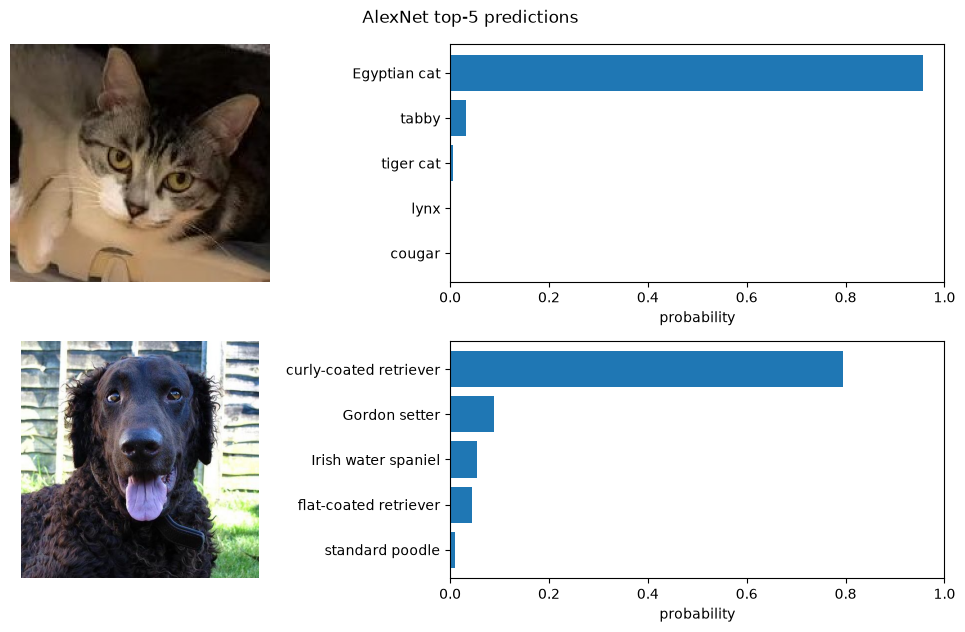

In [36]:
def predict_top5(model, image_path, categories, k=5):
    model.eval()
    xb = imagenet_preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = F.softmax(model(xb)[0], dim=0)
    top_p, top_i = torch.topk(probs, k)
    return [(categories[i], p.item()) for p, i in zip(top_p.cpu(), top_i.cpu())]

def show_predictions(model, paths, categories, title):
    fig, axes = plt.subplots(len(paths), 2, figsize=(10, 3.2 * len(paths)),
                             gridspec_kw={"width_ratios": [1, 1.6]})
    for row, path in zip(axes, paths):
        preds = predict_top5(model, path, categories)
        row[0].imshow(Image.open(path)); row[0].axis("off")
        names, probs = zip(*preds)
        row[1].barh(names[::-1], probs[::-1], color="tab:blue")
        row[1].set_xlim(0, 1); row[1].set_xlabel("probability")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_predictions(alexNet, ["cat.jpg", "dog.jpg"], labels, "AlexNet top-5 predictions")

🧪 **Quick check:** what happens if you forget `imagenet_preprocess`'s `Normalize`, or forget `model.eval()`? Try it!

<details><summary>Answer</summary>

Without normalisation the input statistics differ from training → predictions become less confident or wrong. Without `eval()` dropout stays active → predictions change randomly between runs.
</details>

---
## Part 4 — Going deep: ResNet & transfer learning

He, Zhang, Ren & Sun. *"Deep Residual Learning for Image Recognition."* CVPR 2016.

**Problem:** simply stacking more layers made networks *worse*, even on the training set — very deep plain networks are hard to optimise.

**Why:** Vanishing gradients during backpropagation as the network becomes deeper.

**Solution:** let each block learn only a *residual* $F(x)$ and add the input back through a **skip connection**:

$$y = \text{ReLU}\big(F(x) + x\big)$$

If the extra layers are not useful, the block can simply learn $F(x)\approx 0$ and pass $x$ through. Gradients also flow directly through the "+", which made training of 50, 101 and even 152-layer networks possible.

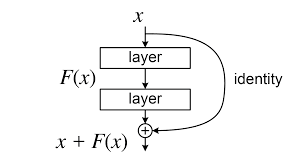

```
Plain CNN block:   x → conv → conv → output
ResNet block:      x → conv → conv → output + x
```

### 4.1 A residual block from scratch

In [ ]:
class BasicBlock(nn.Module):
    """The ResNet-18/34 building block: two 3x3 convs + skip connection."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        # Batch normalization normalizes the activations in a layer so they stay on a more stable scale during training. 
        # In practice, it usually makes training faster and more stable, allows larger learning rates, 
        # and reduces sensitivity to parameter initialization.
        self.bn1 = nn.BatchNorm2d(out_ch) #
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        # 1x1 conv on the skip path when the shape changes, so that out + identity is valid
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # if shape changed (channels or stride), use downsample on the skip
        if self.downsample is not None:
            identity = self.downsample(x)

        # residual connection: a special type of skip connection that adds the skipped input to the output of the convs
        # residual connections help with the vanishing gradient problem and 
        # allow for training deeper networks by providing a direct path for gradients to flow through the network.
        out = out + identity      # <-- THIS is where residual happens
        out = self.relu(out)

        return out

t = torch.randn(2, 64, 56, 56)
print("same shape     :", BasicBlock(64, 64)(t).shape)
print("downsample (s2):", BasicBlock(64, 128, stride=2)(t).shape)

same shape     : torch.Size([2, 64, 56, 56])
downsample (s2): torch.Size([2, 128, 28, 28])


### 4.2 A pretrained ResNet-18 on our cat and dog
ResNet-18 has 18 weight layers built from 8 of these blocks.

BasicBlock(
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (downsample): Sequential(
    (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)

AlexNet  :   61,100,840 params
ResNet-18:   11,689,512 params  (deeper, yet ~5x fewer parameters)


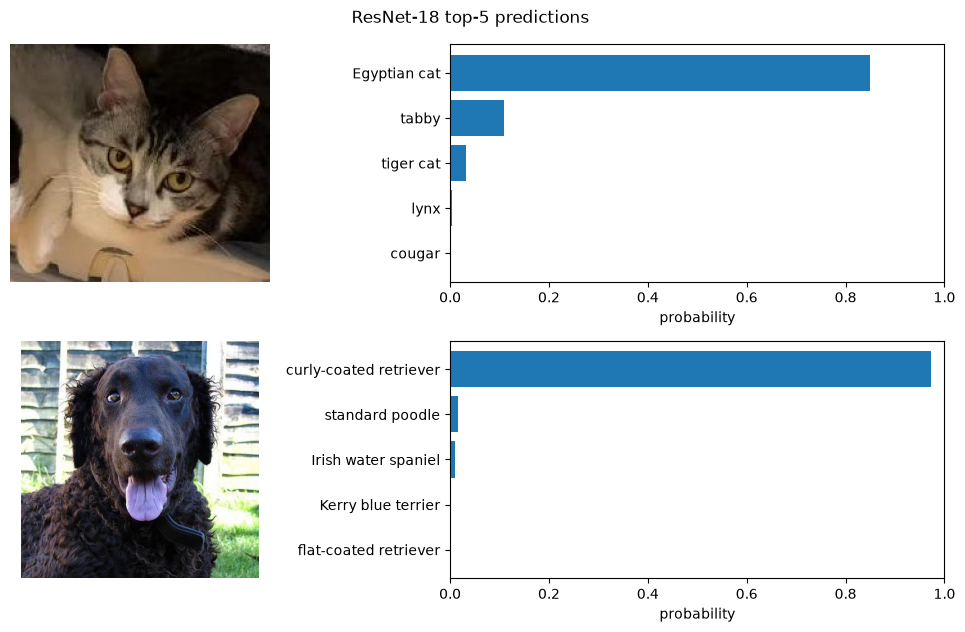

In [38]:
resnet_weights = models.ResNet18_Weights.DEFAULT
resnet_imagenet = models.resnet18(weights=resnet_weights).to(device).eval()

print(resnet_imagenet.layer2[0])   # compare with our BasicBlock!
print(f"\nAlexNet  : {count_params(alexNet):>12,} params")
print(f"ResNet-18: {count_params(resnet_imagenet):>12,} params  (deeper, yet ~5x fewer parameters)")

show_predictions(resnet_imagenet, ["cat.jpg", "dog.jpg"], resnet_weights.meta["categories"],
                 "ResNet-18 top-5 predictions")

### 4.3 Transfer learning: fine-tune ResNet-18 on MNIST

Instead of training from scratch, we reuse a network pretrained on ImageNet and adapt it:

| Strategy | What is trained | When |
|---|---|---|
| **Feature extraction** | only the new head (last layer) | small dataset, similar domain |
| **Partial fine-tuning** | head + a few layers | ← what we do here |
| **Full fine-tuning** | everything (small learning rate) | enough data / different domain |

#### Load the dataset

In [39]:
# --------------------------
# 1. Data Loading
# --------------------------
# MNIST is 28x28 grayscale. We'll keep it at 28x28 here, even though ResNet
# was originally trained on 224x224 color images. (You could also upsample to 224.)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)

if FAST:   # use a random 12k-image subset of the training set to keep class time short
    train_dataset = Subset(train_dataset, torch.randperm(len(train_dataset))[:12000].tolist())

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
print(len(train_dataset), "training images |", len(test_dataset), "test images")

12000 training images | 10000 test images


#### Load the pretrained ResNet and adapt both ends
MNIST has **1 input channel** (not 3) and **10 classes** (not 1000), so we replace the first conv and the final FC layer.
More pretrained models: https://pytorch.org/vision/stable/models.html

In [ ]:
# --------------------------
# 2. Load Pretrained ResNet
# --------------------------
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # (older code: pretrained=True)

print("Before change: First layer (conv)", model.conv1) # because ImageNet1K has 1000 classes.
print("Before change: Last layer (FC)", model.fc)

# --------------------------
# 3. Modify the Network
# --------------------------
# (A) Replace the first conv layer to accept 1-channel input
# The original: nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)

# (B) Replace final FC layer with output size of 10 classes
# ResNet18's fc layer has in_features=512. We set out_features=10 for MNIST.
model.fc = nn.Linear(in_features=512, out_features=10)

print("After change: First layer (conv)", model.conv1)
print("After change: Last layer (FC)", model.fc)

Before change: First layer (conv) Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
Before change: Last layer (FC) Linear(in_features=512, out_features=1000, bias=True)
After change: First layer (conv) Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
After change: Last layer (FC) Linear(in_features=512, out_features=10, bias=True)


In [41]:
print(model)   # long output - scroll through and find conv1, layer1..layer4, avgpool, fc

ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [42]:
# --------------------------
# 4. Move to GPU (if available)
# --------------------------
model.to(device)

# How does a 28x28 digit flow through a network designed for 224x224?
model.eval()
h = torch.zeros(1, 1, 28, 28, device=device)
with torch.no_grad():
    for name in ["conv1", "bn1", "relu", "maxpool", "layer1", "layer2", "layer3", "layer4", "avgpool"]:
        h = getattr(model, name)(h)
        print(f"{name:8s} -> {tuple(h.shape)}")

conv1    -> (1, 64, 14, 14)
bn1      -> (1, 64, 14, 14)
relu     -> (1, 64, 14, 14)
maxpool  -> (1, 64, 7, 7)
layer1   -> (1, 64, 7, 7)
layer2   -> (1, 128, 4, 4)
layer3   -> (1, 256, 2, 2)
layer4   -> (1, 512, 1, 1)
avgpool  -> (1, 512, 1, 1)


#### Freeze most of the pretrained weights

In [43]:
# How many parameters are there?  (the original version of this cell)
num_parameters = 0
for param in model.parameters():
    num_parameters += len(param)
print("len(param) sum :", num_parameters)

# ⚠️ len(param) only returns the size of the FIRST dimension
# (e.g. 64 for a 64x3x7x7 kernel). Use .numel() to count all elements:
print("numel() sum    :", sum(p.numel() for p in model.parameters()))

len(param) sum : 14420
numel() sum    : 11175370


In [44]:
# --------------------------
# 5. Freeze major parts of pre-trained weights
# --------------------------
# Freeze all parameters first, then unfreeze parts
for param in model.parameters():
    param.requires_grad = False

# Unfreeze just the first layer (new, randomly initialised):
for param in model.conv1.parameters():
    param.requires_grad = True

# Unfreeze the final layer (new, randomly initialised):
for param in model.fc.parameters():
    param.requires_grad = True

print(f"trainable: {count_params(model, trainable_only=True):,} / {count_params(model):,} parameters")

# --------------------------
# 6. Define Loss and Optimizer (give the optimizer only the trainable parameters)
# --------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)

trainable: 8,266 / 11,175,370 parameters


💡 `requires_grad=False` freezes *weights*, but BatchNorm layers in `train()` mode still update their running mean/variance. Here that actually helps: the statistics adapt from ImageNet photos to MNIST digits.

#### Helper to evaluate the model

In [45]:
def evaluate_model(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100.0 * correct / total
    return accuracy

In [46]:
# --------------------------
# 7. Training Loop
# --------------------------
num_epochs = 2 if FAST else 5

# Accuracy of the model BEFORE fine-tuning (new conv1 and fc are random -> ~10% = chance)
train_accuracy = evaluate_model(model, train_loader)
test_accuracy = evaluate_model(model, test_loader)
print(f"Epoch [0/{num_epochs}], Loss: [Not fine-tuned yet], "
      f"Train Accuracy: {train_accuracy:.2f}%, Test Accuracy: {test_accuracy:.2f}%")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    start = time.time()

    for images, labels in tqdm(train_loader, leave=False):
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Print average training loss for this epoch
    epoch_loss = running_loss / len(train_loader)
    train_accuracy = evaluate_model(model, train_loader)
    test_accuracy = evaluate_model(model, test_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, "
          f"Test Accuracy: {test_accuracy:.2f}%  ({time.time() - start:.0f}s)")

results["ResNet-18 (frozen body)"] = test_accuracy

Epoch [0/2], Loss: [Not fine-tuned yet], Train Accuracy: 7.59%, Test Accuracy: 7.58%


  0%|          | 0/188 [00:00<?, ?it/s]

Epoch [1/2], Loss: 1.5163, Train Accuracy: 70.41%, Test Accuracy: 69.16%  (302s)


  0%|          | 0/188 [00:00<?, ?it/s]

Epoch [2/2], Loss: 0.8617, Train Accuracy: 81.43%, Test Accuracy: 80.39%  (303s)


🧪 **Try it (choose one):**

1. **Unfreeze more:** also train `model.layer4` (or everything) with a smaller learning rate. Does accuracy improve? How much slower is an epoch?
2. **Keep the pretrained first layer:** instead of a random `conv1`, average the pretrained RGB kernels into one grayscale kernel.
3. **Upsample** the digits to 224×224 (`transforms.Resize(224)`) so the input matches the pretraining resolution.

<details><summary>Hints</summary>

```python
# 1. unfreeze layer4 too
for p in model.layer4.parameters():
    p.requires_grad = True
optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

# 2. reuse the pretrained conv1 by averaging over the RGB input channels
pretrained = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
new_conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
new_conv1.weight.data = pretrained.conv1.weight.data.mean(dim=1, keepdim=True)
model.conv1 = new_conv1.to(device)

# 3. upsample in the transform
transform = transforms.Compose([transforms.Resize(224), transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])
```
</details>

---
## Wrap-up

In [47]:
print(f"{'Model':28s} {'MNIST test acc':>15s}")
for name, acc in results.items():
    print(f"{name:28s} {acc:>14.2f}%")

Model                         MNIST test acc
Small CNN (ours)                      96.80%
ResNet-18 (frozen body)               80.39%


| Model | Year | Key idea | Params |
|---|---|---|---|
| LeNet-style CNN (Part 2) | 1998 | conv → pool → FC, weight sharing | ~1.3 k (ours) |
| **AlexNet** | 2012 | big CNN + ReLU + dropout + GPUs | 61 M |
| VGG-16 | 2014 | only stacked 3×3 convs, very deep & uniform | 138 M |
| GoogLeNet / Inception | 2014 | parallel multi-scale branches, 1×1 convs, global avg pool | 6.6 M |
| **ResNet** | 2015 | residual (skip) connections → 100+ layers | 11.7 M (R18) |
| U-Net | 2015 | encoder–decoder + skip *concatenation* for segmentation | task-dependent |
| MobileNet / EfficientNet | 2017–19 | depthwise-separable convs, compound scaling | 2–5 M |
| ConvNeXt | 2022 | ResNet modernised with Transformer-era design choices | 28 M (Tiny) |

**Take-aways**
* A convolution is a small, shared, learnable filter; padding and stride control output size.
* CNNs stack conv → non-linearity → pooling to go from pixels to edges to parts to objects.
* Depth needs help to train: ReLU, BatchNorm and especially **residual connections**.
* **Transfer learning**: reuse pretrained features, replace the head, freeze what you don't need to train.

---
# ⭐ Optional sections (homework / if time allows)

## A. A tour of the CNN zoo
Two design ideas behind many post-AlexNet models — and how the models compare.

In [48]:
# (1) VGG idea: two stacked 3x3 convs see a 5x5 region (three see 7x7) with fewer params + more non-linearities
C = 256
one_5x5 = nn.Conv2d(C, C, 5, padding=2, bias=False)
two_3x3 = nn.Sequential(nn.Conv2d(C, C, 3, padding=1, bias=False), nn.ReLU(),
                        nn.Conv2d(C, C, 3, padding=1, bias=False))
print(f"one 5x5 conv : {count_params(one_5x5):>9,} params")
print(f"two 3x3 convs: {count_params(two_3x3):>9,} params  (same 5x5 receptive field)")

# (2) MobileNet idea: depthwise-separable conv = per-channel 3x3 conv + 1x1 conv that mixes channels
standard = nn.Conv2d(128, 256, 3, padding=1, bias=False)
separable = nn.Sequential(nn.Conv2d(128, 128, 3, padding=1, groups=128, bias=False),  # depthwise
                          nn.Conv2d(128, 256, 1, bias=False))                          # pointwise
t = torch.randn(1, 128, 32, 32)
print(f"\nstandard 3x3 conv  : {count_params(standard):>9,} params, output {tuple(standard(t).shape)}")
print(f"depthwise-separable: {count_params(separable):>9,} params, output {tuple(separable(t).shape)}")

one 5x5 conv : 1,638,400 params
two 3x3 convs: 1,179,648 params  (same 5x5 receptive field)

standard 3x3 conv  :   294,912 params, output (1, 256, 32, 32)
depthwise-separable:    33,920 params, output (1, 256, 32, 32)


model                    params (M)  top-1 (%)
AlexNet (2012)                 61.1       56.5
VGG-16 (2014)                 138.4       71.6
GoogLeNet (2014)                6.6       69.8
ResNet-18 (2015)               11.7       69.8
ResNet-50 (2015)               25.6       76.1
MobileNetV3-S (2019)            2.5       67.7
EfficientNet-B0 (2019)          5.3       77.7
ConvNeXt-T (2022)              28.6       82.5


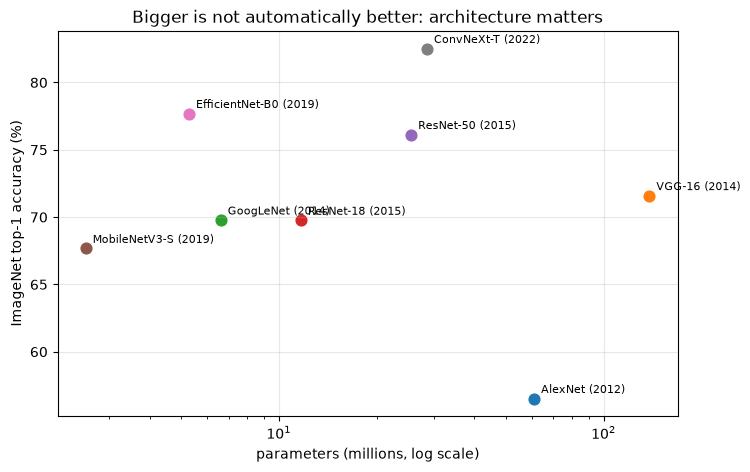

In [49]:
# Parameters vs. ImageNet accuracy, read from torchvision's weight metadata (no download needed)
def top1(w):
    meta = w.meta
    if "_metrics" in meta: return meta["_metrics"]["ImageNet-1K"]["acc@1"]
    if "metrics" in meta:  return meta["metrics"]["acc@1"]
    return float("nan")

zoo = {
    "AlexNet (2012)":         models.AlexNet_Weights.IMAGENET1K_V1,
    "VGG-16 (2014)":          models.VGG16_Weights.IMAGENET1K_V1,
    "GoogLeNet (2014)":       models.GoogLeNet_Weights.IMAGENET1K_V1,
    "ResNet-18 (2015)":       models.ResNet18_Weights.IMAGENET1K_V1,
    "ResNet-50 (2015)":       models.ResNet50_Weights.IMAGENET1K_V1,
    "MobileNetV3-S (2019)":   models.MobileNet_V3_Small_Weights.IMAGENET1K_V1,
    "EfficientNet-B0 (2019)": models.EfficientNet_B0_Weights.IMAGENET1K_V1,
    "ConvNeXt-T (2022)":      models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1,
}
print(f"{'model':24s} {'params (M)':>10s} {'top-1 (%)':>10s}")
plt.figure(figsize=(8, 5))
for name, w in zoo.items():
    p, acc = w.meta["num_params"] / 1e6, top1(w)
    print(f"{name:24s} {p:>10.1f} {acc:>10.1f}")
    plt.scatter(p, acc, s=60)
    plt.annotate(name, (p, acc), textcoords="offset points", xytext=(5, 4), fontsize=8)
plt.xscale("log"); plt.xlabel("parameters (millions, log scale)"); plt.ylabel("ImageNet top-1 accuracy (%)")
plt.title("Bigger is not automatically better: architecture matters"); plt.grid(alpha=0.3)
plt.show()

## B. Where is the network looking? Grad-CAM
Grad-CAM (Selvaraju et al., 2017) weights the last conv feature maps by the gradient of the class score and shows which regions drove the decision. We use **hooks** to grab activations and gradients of `layer4` of the pretrained ResNet-18.

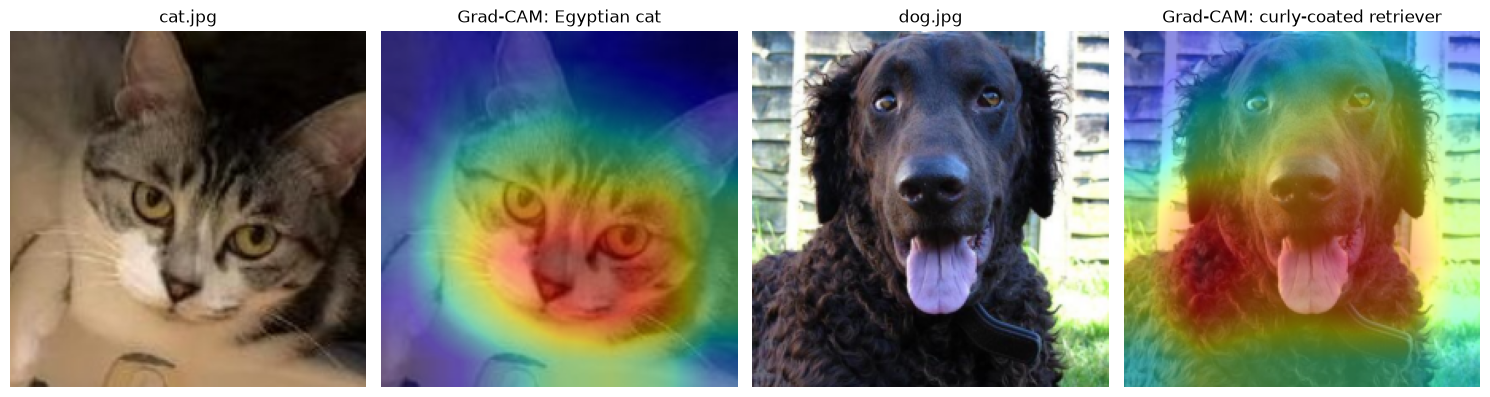

In [50]:
def gradcam(model, x, target_layer, class_idx=None):
    store = {}
    def fwd_hook(module, inp, out):
        store["act"] = out
        out.register_hook(lambda g: store.__setitem__("grad", g))   # gradient w.r.t. this output
    handle = target_layer.register_forward_hook(fwd_hook)
    model.eval()
    logits = model(x)                   # NOTE: no torch.no_grad() here, we need gradients
    handle.remove()
    if class_idx is None:
        class_idx = logits.argmax(1).item()
    model.zero_grad()
    logits[0, class_idx].backward()
    weights = store["grad"].mean(dim=(2, 3), keepdim=True)           # importance of each channel
    cam = torch.relu((weights * store["act"]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam[0, 0].detach().cpu(), class_idx

crop = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
cats = resnet_weights.meta["categories"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for k, path in enumerate(["cat.jpg", "dog.jpg"]):
    pil = Image.open(path).convert("RGB")
    xb = imagenet_preprocess(pil).unsqueeze(0).to(device)
    cam, idx = gradcam(resnet_imagenet, xb, resnet_imagenet.layer4)
    axes[2 * k].imshow(crop(pil)); axes[2 * k].axis("off"); axes[2 * k].set_title(path)
    axes[2 * k + 1].imshow(crop(pil)); axes[2 * k + 1].imshow(cam, cmap="jet", alpha=0.45)
    axes[2 * k + 1].axis("off"); axes[2 * k + 1].set_title(f"Grad-CAM: {cats[idx]}")
plt.tight_layout(); plt.show()

🧪 Pass a different `class_idx` (e.g. `cats.index("tennis ball")`) — where does the network look for *that* class?

## C. Data augmentation
AlexNet already used random crops and flips. Augmentation creates new, label-preserving variations of the training images so the network learns invariances instead of memorising.

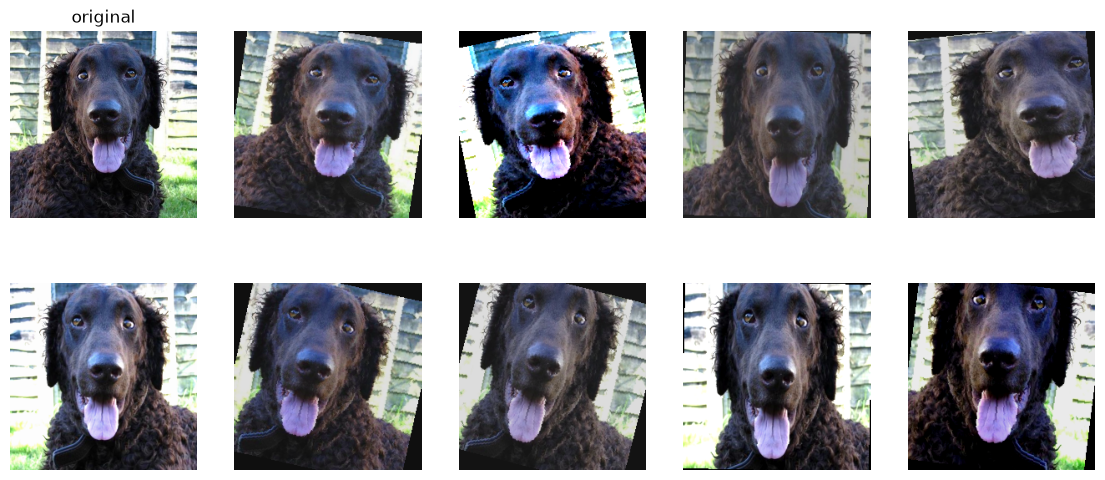

In [51]:
augment = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.05),
])
dog = Image.open("dog.jpg").convert("RGB")
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes.flat[0].imshow(dog); axes.flat[0].set_title("original")
for ax in axes.flat[1:]:
    ax.imshow(augment(dog))
for ax in axes.flat: ax.axis("off")
plt.show()
# For MNIST, which of these would be a BAD idea?  (Hint: flip a 2, rotate a 6 by 180°...)

## D. U-Net: from classification to segmentation
Ronneberger, Fischer & Brox. *"U-Net: Convolutional Networks for Biomedical Image Segmentation."* MICCAI 2015.

Classification gives **one label per image**; segmentation needs **one label per pixel**. U-Net is an encoder–decoder:
* **Encoder** (left side of the "U"): conv blocks + pooling, like a normal CNN → *what* is in the image.
* **Decoder** (right side): **transposed convolutions** upsample back to full resolution → *where* it is.
* **Skip connections** *concatenate* encoder features into the decoder to recover fine detail (ResNet *adds*, U-Net *concatenates*).

```
64x64 ─enc1──────────────────────────(concat)──dec1─ 1x1 conv → 11 class scores per pixel
        32x32 ─enc2───────────(concat)──dec2─┘
               16x16 ─enc3─(concat)─dec3─┘
                      8x8 ─bottleneck─┘
```

**Toy task — "MNIST scenes":** we paste 1–3 digits onto a 64×64 canvas. Each pixel gets a label: 0 = background, *d*+1 = digit *d*.

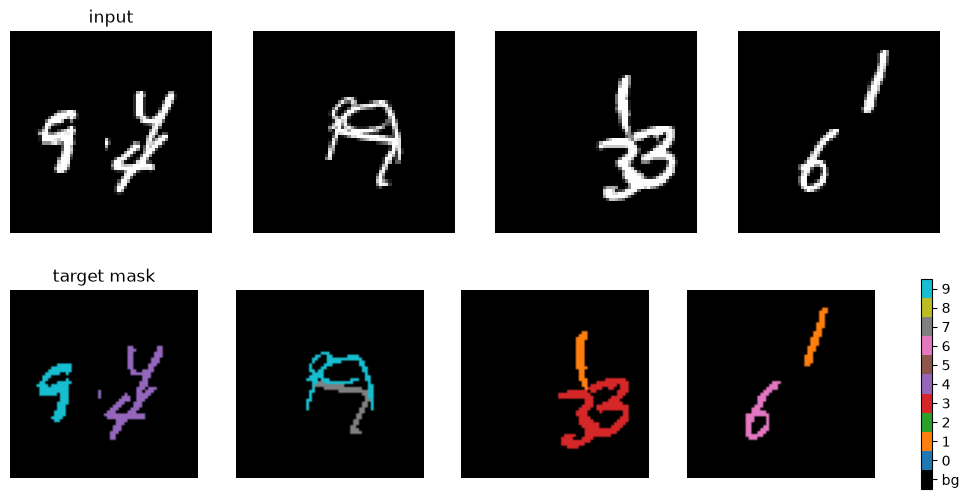

In [52]:
def make_seg_dataset(base, n_samples, canvas=64, max_digits=3, seed=0):
    g = torch.Generator().manual_seed(seed)
    data = base.data.float() / 255.0          # (N, 28, 28) raw MNIST digits in [0, 1]
    targets = base.targets
    X = torch.zeros(n_samples, 1, canvas, canvas)
    Y = torch.zeros(n_samples, canvas, canvas, dtype=torch.long)
    for n in range(n_samples):
        k = torch.randint(1, max_digits + 1, (1,), generator=g).item()
        for _ in range(k):
            idx = torch.randint(0, len(data), (1,), generator=g).item()
            r, c = torch.randint(0, canvas - 28 + 1, (2,), generator=g).tolist()
            digit = data[idx]
            X[n, 0, r:r+28, c:c+28] = torch.maximum(X[n, 0, r:r+28, c:c+28], digit)
            Y[n, r:r+28, c:c+28][digit > 0.5] = targets[idx] + 1
    return X, Y

raw_train = datasets.MNIST("data", train=True, download=True)
raw_test = datasets.MNIST("data", train=False, download=True)
Xtr, Ytr = make_seg_dataset(raw_train, 3000 if FAST else 20000, seed=0)
Xte, Yte = make_seg_dataset(raw_test, 500, seed=1)
seg_train_loader = DataLoader(TensorDataset(Xtr, Ytr), batch_size=32, shuffle=True)
seg_test_loader = DataLoader(TensorDataset(Xte, Yte), batch_size=64)

from matplotlib.colors import ListedColormap
seg_cmap = ListedColormap(["black"] + [plt.cm.tab10(i) for i in range(10)])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    axes[0, k].imshow(Xtr[k, 0], cmap="gray"); axes[0, k].axis("off")
    im = axes[1, k].imshow(Ytr[k], cmap=seg_cmap, vmin=-0.5, vmax=10.5); axes[1, k].axis("off")
cb = fig.colorbar(im, ax=axes[1, :], ticks=range(11), fraction=0.02)
cb.ax.set_yticklabels(["bg"] + [str(d) for d in range(10)])
axes[0, 0].set_title("input"); axes[1, 0].set_title("target mask")
plt.show()

In [53]:
def double_conv(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, n_classes=11, base=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        # encoder
        self.enc1 = double_conv(in_ch, base)              # 64x64
        self.enc2 = double_conv(base, base * 2)           # 32x32
        self.enc3 = double_conv(base * 2, base * 4)       # 16x16
        self.bottleneck = double_conv(base * 4, base * 8) # 8x8
        # decoder: upsample, concatenate the skip, then convolve
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, kernel_size=2, stride=2)
        self.dec3 = double_conv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, kernel_size=2, stride=2)
        self.dec2 = double_conv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, kernel_size=2, stride=2)
        self.dec1 = double_conv(base * 2, base)
        self.head = nn.Conv2d(base, n_classes, kernel_size=1)   # per-pixel classifier

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))   # skip connection = concatenation
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

unet = UNet().to(device)
print(f"U-Net parameters: {count_params(unet):,}")
print("output shape:", unet(Xtr[:2].to(device)).shape, "-> (N, classes, H, W)")

U-Net parameters: 483,323
output shape: torch.Size([2, 11, 64, 64]) -> (N, classes, H, W)


In [54]:
def seg_metrics(model, loader, n_classes=11):
    """Pixel accuracy and mean IoU over the 10 digit classes."""
    model.eval()
    inter, union = torch.zeros(n_classes), torch.zeros(n_classes)
    correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).argmax(dim=1)
            correct += (pred == yb).sum().item(); total += yb.numel()
            for c in range(n_classes):
                p, t = pred == c, yb == c
                inter[c] += (p & t).sum().item(); union[c] += (p | t).sum().item()
    iou = inter / union.clamp(min=1)
    return 100 * correct / total, 100 * iou[1:].mean().item()

seg_optimizer = optim.Adam(unet.parameters(), lr=1e-3)
seg_criterion = nn.CrossEntropyLoss()        # works per pixel: logits (N,C,H,W) vs labels (N,H,W)
for epoch in range(4 if FAST else 10):
    unet.train()
    losses = []
    for xb, yb in tqdm(seg_train_loader, leave=False):
        xb, yb = xb.to(device), yb.to(device)
        loss = seg_criterion(unet(xb), yb)
        seg_optimizer.zero_grad(); loss.backward(); seg_optimizer.step()
        losses.append(loss.item())
    pix_acc, miou = seg_metrics(unet, seg_test_loader)
    print(f"epoch {epoch + 1}: loss {np.mean(losses):.4f} | pixel acc {pix_acc:.2f}% | digit mIoU {miou:.1f}%")

  0%|          | 0/94 [00:00<?, ?it/s]

epoch 1: loss 1.4566 | pixel acc 95.48% | digit mIoU 4.3%


  0%|          | 0/94 [00:00<?, ?it/s]

epoch 2: loss 0.5916 | pixel acc 95.67% | digit mIoU 4.7%


  0%|          | 0/94 [00:00<?, ?it/s]

epoch 3: loss 0.2684 | pixel acc 95.70% | digit mIoU 4.3%


  0%|          | 0/94 [00:00<?, ?it/s]

epoch 4: loss 0.1769 | pixel acc 96.17% | digit mIoU 12.1%


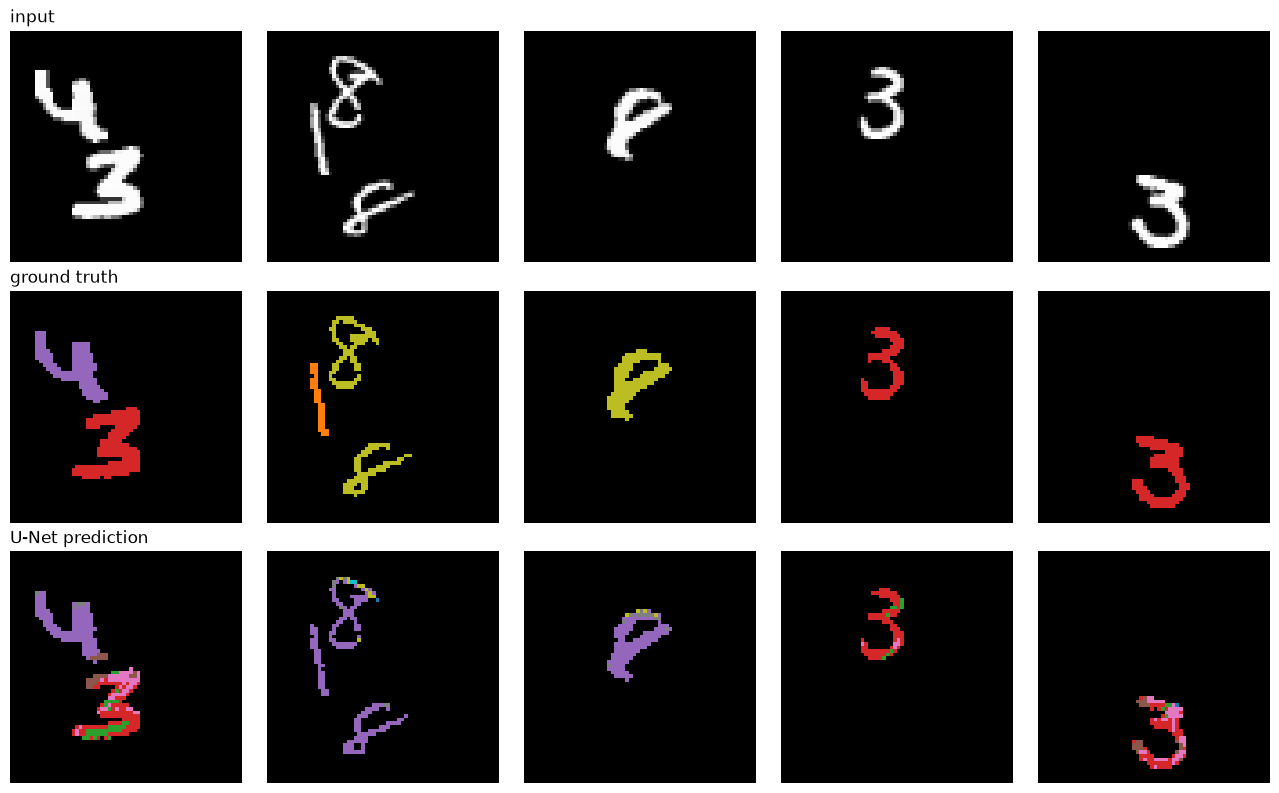

In [55]:
unet.eval()
with torch.no_grad():
    pred = unet(Xte[:5].to(device)).argmax(dim=1).cpu()
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for k in range(5):
    axes[0, k].imshow(Xte[k, 0], cmap="gray")
    axes[1, k].imshow(Yte[k], cmap=seg_cmap, vmin=-0.5, vmax=10.5)
    axes[2, k].imshow(pred[k], cmap=seg_cmap, vmin=-0.5, vmax=10.5)
for ax in axes.flat: ax.axis("off")
for r, t in enumerate(["input", "ground truth", "U-Net prediction"]):
    axes[r, 0].set_title(t, loc="left")
plt.tight_layout(); plt.show()

🧪 **Try it:** remove the skip connections (decode only from the bottleneck, adjusting channel counts). What happens to the digit boundaries and the mIoU?

---
### References
* LeCun et al. (1998). *Gradient-based learning applied to document recognition.* (LeNet)
* Krizhevsky, Sutskever & Hinton (2012). *ImageNet classification with deep CNNs.* (AlexNet)
* Simonyan & Zisserman (2015). *Very deep convolutional networks for large-scale image recognition.* (VGG)
* Szegedy et al. (2015). *Going deeper with convolutions.* (GoogLeNet)
* He et al. (2016). *Deep residual learning for image recognition.* (ResNet)
* Ronneberger, Fischer & Brox (2015). *U-Net: Convolutional networks for biomedical image segmentation.*
* Selvaraju et al. (2017). *Grad-CAM: Visual explanations from deep networks via gradient-based localization.*
* Howard et al. (2019) MobileNetV3 · Tan & Le (2019) EfficientNet · Liu et al. (2022) ConvNeXt
* PyTorch vision models: https://pytorch.org/vision/stable/models.html